In [5]:
# IMPORTS
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, img_as_float
from skimage.util import random_noise
import torch
from ipywidgets import interact
import ipywidgets as widgets
from skimage.metrics import structural_similarity as ssim
from torch.fft import fft2, ifft2, fftshift, ifftshift
import tempfile
import IPython
from skimage.transform import rescale

In [6]:
# IMAGES RELATED METHODS
def to_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    elif isinstance(x, np.ndarray):
        return x
    else:
        raise TypeError(f"Tipo inesperado: {type(x)}")

def show_images(imgs, titles=None, cmap='gray', figsize=(12,4)):
    n = len(imgs)
    fig, axs = plt.subplots(1, n, figsize=figsize)
    if n == 1: axs = [axs]
    for i, im in enumerate(imgs):
        axs[i].imshow(to_numpy(im), cmap=cmap)
        if titles: axs[i].set_title(titles[i])
        axs[i].axis('off')
    plt.show()


In [7]:
# METRICS METHODS

def rmse_np(ref, est):
    return np.sqrt(np.mean((ref - est) ** 2))

def mse_np(ref, est):
    return np.mean((ref - est)**2)

def ssim_np(ref, est):
    return ssim(ref, est, data_range=1.0)

def mae_np(ref, est):
    return np.mean(np.abs(ref - est))

def psnr_np(ref, est):
    rmse = rmse_np(ref, est)
    if rmse == 0:
        return np.inf
    return 20 * np.log10(1.0 / rmse)



In [8]:
# GRADIENT METHODS
def gradient_x(u):
    gx = torch.zeros_like(u)
    gx[:, :-1] = u[:, 1:] - u[:, :-1]
    return gx

def gradient_y(u):
    gy = torch.zeros_like(u)
    gy[:-1, :] = u[1:, :] - u[:-1, :]
    return gy


In [9]:
# REGULARISATION FONCTIONS
def tykhonov_reg(u):
    """Régularisation de tykonov : ||∇u||²"""
    gx, gy = gradient_x(u), gradient_y(u)
    return (gx**2 + gy**2).sum()

def tv_reg(u, eps = 0.001):
    gx, gy = gradient_x(u), gradient_y(u)
    return torch.sqrt(gx**2 + gy**2 + eps**2).sum()

# Applies the gradient descent 
def optimize_image(v, lam=0.05, lr=0.5, n_iter=200, reg_fn=None, record_loss=False):
    """
    Résout : min_u  0.5‖u - v‖² + λ * reg_fn(u)
    """
    assert reg_fn is not None, "Tu dois donner une fonction de régularisation reg_fn(u)"

    u = v.detach().clone().float().requires_grad_(True)
    opt = torch.optim.SGD([u], lr=lr)
    losses = []

    for _ in range(n_iter):
        opt.zero_grad(set_to_none=True)

        fidelity = 0.5 * torch.sum((u - v)**2)
        # fidelity = 0.5 * torch.mean((u - v)**2)
        reg = lam * reg_fn(u)

        loss = fidelity + reg #fonction à minimiser

        loss.backward()
        opt.step()

        with torch.no_grad():
            u.clamp_(0, 1)

        if record_loss:
            losses.append(loss.item())

    return (u.detach(), losses) if record_loss else u.detach()






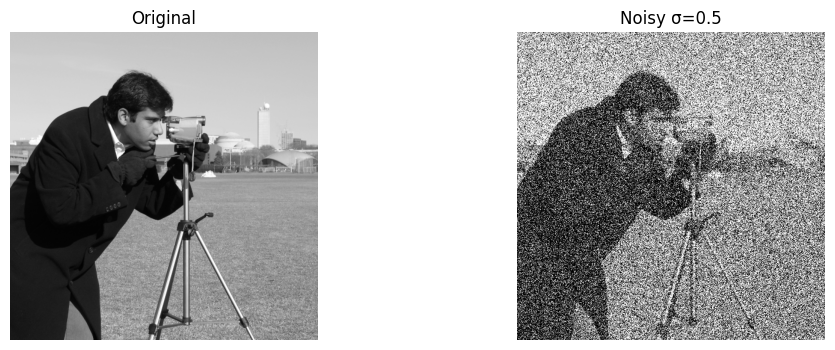

In [10]:
# -----------------------------------------------------------------------------
# DENOISING

u0 = img_as_float(data.camera())  # clean image
M, N = u0.shape
sigma = 0.5
v = random_noise(u0, mode='gaussian', var=sigma**2)
v_torch = torch.tensor(v, dtype=torch.float32)

show_images([u0, v], titles=["Original", f"Noisy σ={sigma}"])

In [11]:
# DENOISING - TYKHONOV ANALYTIC

def tykonov_fourier(v, lam):
    """Solution tykonov explicite avec conditions périodiques."""
    M, N = v.shape
    xi = np.arange(M)
    zeta = np.arange(N)
    xi, zeta = np.meshgrid(xi, zeta, indexing='ij')
    L_hat = 4 * (np.sin(np.pi * xi / M) ** 2 + np.sin(np.pi * zeta / N) ** 2)
    v_hat = fft2(v)
    u_hat = v_hat / (1 + 2 * lam * L_hat)
    u_rec = np.real(ifft2(u_hat))
    return u_rec



/var/folders/tr/h5v707gx7mx1xv9zf0xpkb5c0000gn/T/ipykernel_34586/3656911421.py:11: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  u_hat = v_hat / (1 + 2 * lam * L_hat)


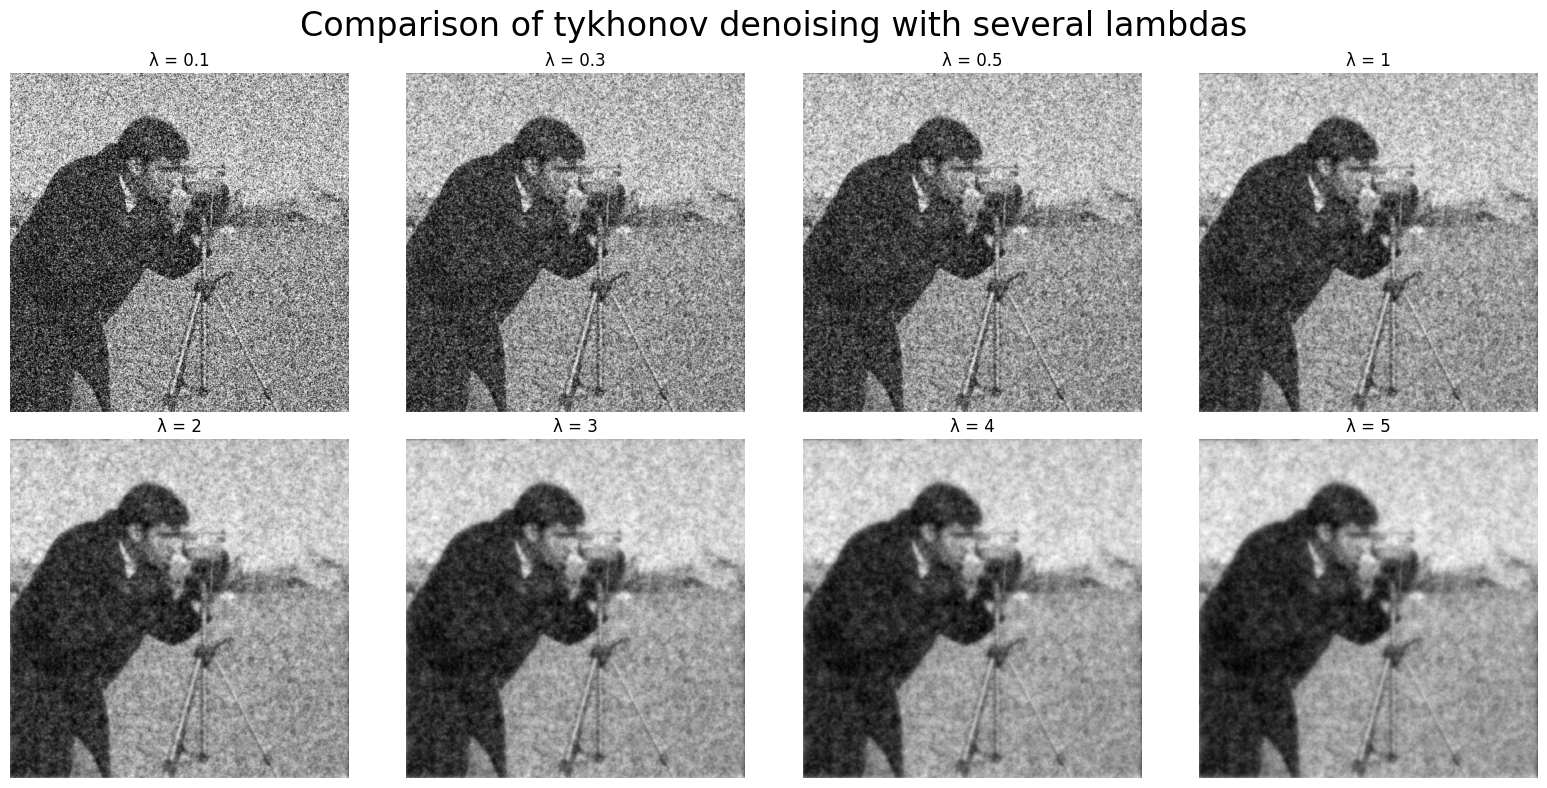

In [12]:
# TEST WITH SEVERAL LAMBDAS
lambdas_tyk = [0.1, 0.3, 0.5, 1, 2, 3, 4, 5]
lrs_tyk = [1 / (1 + 16 * lam) for lam in lambdas_tyk] 
results = [(lam, tykonov_fourier(v_torch, lam)) for lam in lambdas_tyk]


# visualisation
fig, axes = plt.subplots(2, 4, figsize=(16, 8))


for ax, (lam, u_img) in zip(axes.flatten(), results):
    ax.imshow(u_img, cmap='gray')
    ax.set_title(f"λ = {lam}")
    ax.axis('off')
fig.suptitle("Comparison of tykhonov denoising with several lambdas", fontsize=24)
plt.subplots_adjust(top=0.88)

plt.tight_layout()
plt.show()


In [13]:
#### metrics table
best_lambda = 2 

# header
print(f"{'λ':>6} | {'PSNR':>7} | {'SSIM':>6} | {'RMSE':>6} | {'MAE':>6}")
print(f"{'':>6} | {'(↑)':>7} | {'(↑)':>6} | {'(↓)':>6} | {'(↓)':>6}")
print("-"*60)

for lam in lambdas_tyk:
    u_fourier = tykonov_fourier(v_torch, lam)
    if isinstance(u_fourier, torch.Tensor):
        u_fourier_np = u_fourier.detach().cpu().numpy()
    else:
        u_fourier_np = np.array(u_fourier)
    psnr_val = psnr_np(u0, u_fourier_np)
    ssim_val = ssim_np(u0, u_fourier_np)
    rmse_val = rmse_np(u0, u_fourier_np)
    mae_val  = mae_np(u0, u_fourier_np)

    mark = "  <--- best" if lam == best_lambda else ""
    print(f"{lam:>6} | {psnr_val:>7.2f} | {ssim_val:>6.3f} | "
          f"{rmse_val:>6.3f} | {mae_val:>6.3f}{mark}")


     λ |    PSNR |   SSIM |   RMSE |    MAE
       |     (↑) |    (↑) |    (↓) |    (↓)
------------------------------------------------------------
   0.1 |   12.92 |  0.086 |  0.226 |  0.174
   0.3 |   15.52 |  0.136 |  0.167 |  0.132
   0.5 |   16.55 |  0.173 |  0.149 |  0.120
     1 |   17.48 |  0.244 |  0.134 |  0.111
     2 |   17.87 |  0.337 |  0.128 |  0.108  <--- best
     3 |   17.92 |  0.394 |  0.127 |  0.108
     4 |   17.89 |  0.430 |  0.127 |  0.109
     5 |   17.85 |  0.454 |  0.128 |  0.110


/var/folders/tr/h5v707gx7mx1xv9zf0xpkb5c0000gn/T/ipykernel_34586/3656911421.py:11: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  u_hat = v_hat / (1 + 2 * lam * L_hat)


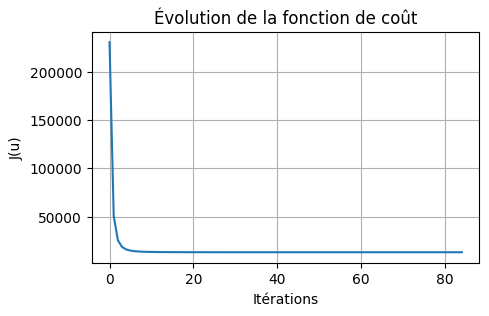

Convergence at iteration: 34


In [14]:
# DENOISING - TYKHONV PYTORCH

# arbitrary value of lambda in order to visualize the loss function
lam = 2
lr = 1/(1+16*lam)

u_rec, loss_values = optimize_image(v_torch, lam=lam, lr = lr, n_iter=85, reg_fn=tykhonov_reg, record_loss=True)

plt.figure(figsize=(5,3))
plt.plot(loss_values)
plt.title("Évolution de la fonction de coût")
plt.xlabel("Itérations")
plt.ylabel("J(u)")
plt.grid(True)
plt.show()

# === compute convergence iteration ===
loss_arr = np.array(loss_values)
smooth_d = np.convolve(np.abs(np.diff(loss_arr)), np.ones(50)/50, mode='valid')

thr = 1e-1
idx = np.where(smooth_d < thr)[0]

print("Convergence at iteration:", idx[0] if len(idx)>0 else "not detected")


<>:83: SyntaxWarning: invalid escape sequence '\l'
<>:83: SyntaxWarning: invalid escape sequence '\l'
/var/folders/tr/h5v707gx7mx1xv9zf0xpkb5c0000gn/T/ipykernel_34586/3464681678.py:83: SyntaxWarning: invalid escape sequence '\l'
  plt.title('PSNR, SSIM, MSE et MAE normalisés en fonction de $\lambda$')
/var/folders/tr/h5v707gx7mx1xv9zf0xpkb5c0000gn/T/ipykernel_34586/3656911421.py:11: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  u_hat = v_hat / (1 + 2 * lam * L_hat)


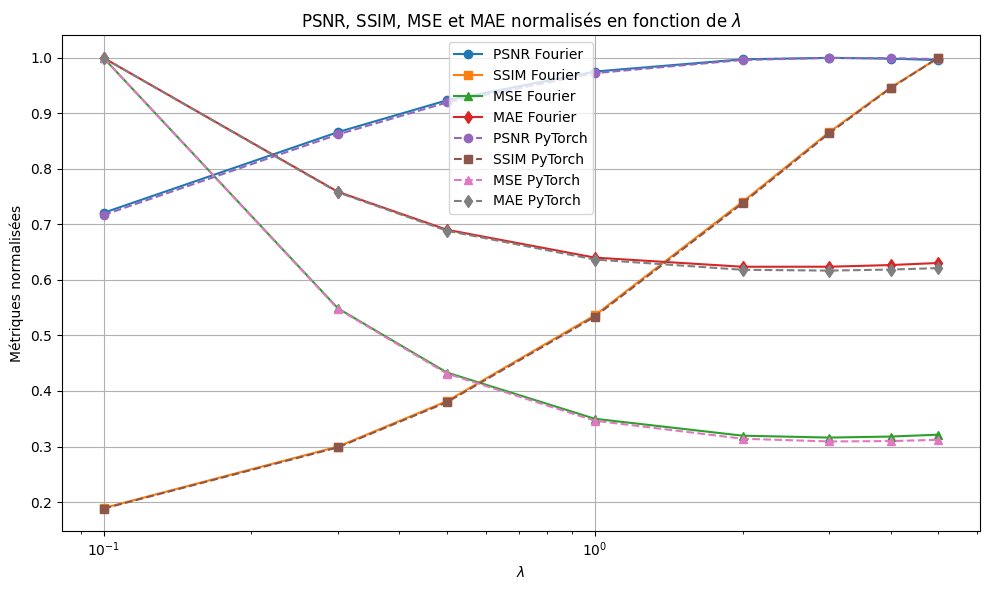

In [15]:
# DENOISING - COMPARAISON BETWEEN TYKHONOV FOURIER AND PYTORCH TO CHECK CONSISTANCY

psnr_fourier_list = []
psnr_pytorch_list = []
ssim_fourier_list = []
ssim_pytorch_list = []
mse_fourier_list = []
mse_pytorch_list = []
mae_fourier_list = []
mae_pytorch_list = []

v_torch_base = torch.tensor(v, dtype=torch.float32)

for lam, lr in zip(lambdas_tyk, lrs_tyk):

    # --- Fourier ---
    u_fourier = tykonov_fourier(v_torch_base, lam)

    # conversion en numpy
    if isinstance(u_fourier, torch.Tensor):
        u_fourier_np = u_fourier.detach().cpu().numpy()
    else:
        u_fourier_np = np.array(u_fourier)

    psnr_fourier_list.append(psnr_np(u0, u_fourier_np))
    ssim_fourier_list.append(ssim(u0, u_fourier_np, data_range=1.0))
    mse_fourier_list.append(np.mean((u0 - u_fourier_np) ** 2))
    mae_fourier_list.append(np.mean(np.abs(u0 - u_fourier_np)))

    # --- PyTorch / descente de gradient ---
    v_torch = v_torch_base.clone()
    n_iter = 500
    u_pytorch, _ = optimize_image(v_torch, lam, lr, n_iter, reg_fn=tykhonov_reg, record_loss=True)

    u_pytorch_np = u_pytorch.detach().cpu().numpy()
    psnr_pytorch_list.append(psnr_np(u0, u_pytorch_np))
    ssim_pytorch_list.append(ssim(u0, u_pytorch_np, data_range=1.0))
    mse_pytorch_list.append(np.mean((u0 - u_pytorch_np) ** 2))
    mae_pytorch_list.append(np.mean(np.abs(u0 - u_pytorch_np)))


# --- conversion numpy ---
psnr_fourier = np.array(psnr_fourier_list)
ssim_fourier = np.array(ssim_fourier_list)
mse_fourier  = np.array(mse_fourier_list)
mae_fourier  = np.array(mae_fourier_list)

psnr_pytorch = np.array(psnr_pytorch_list)
ssim_pytorch = np.array(ssim_pytorch_list)
mse_pytorch  = np.array(mse_pytorch_list)
mae_pytorch  = np.array(mae_pytorch_list)

# --- normalisation ---
psnr_fourier_n = psnr_fourier / psnr_fourier.max()
ssim_fourier_n = ssim_fourier / ssim_fourier.max()
mse_fourier_n  = mse_fourier  / mse_fourier.max()
mae_fourier_n  = mae_fourier  / mae_fourier.max()

psnr_pytorch_n = psnr_pytorch / psnr_pytorch.max()
ssim_pytorch_n = ssim_pytorch / ssim_pytorch.max()
mse_pytorch_n  = mse_pytorch  / mse_pytorch.max()
mae_pytorch_n  = mae_pytorch  / mae_pytorch.max()


# --- affichage sur un seul graphique ---
plt.figure(figsize=(10, 6))

# Fourier
plt.plot(lambdas_tyk, psnr_fourier_n, marker='o', linestyle='-',  label='PSNR Fourier')
plt.plot(lambdas_tyk, ssim_fourier_n, marker='s', linestyle='-',  label='SSIM Fourier')
plt.plot(lambdas_tyk, mse_fourier_n,  marker='^', linestyle='-',  label='MSE Fourier')
plt.plot(lambdas_tyk, mae_fourier_n,  marker='d', linestyle='-',  label='MAE Fourier')

# PyTorch
plt.plot(lambdas_tyk, psnr_pytorch_n, marker='o', linestyle='--', label='PSNR PyTorch')
plt.plot(lambdas_tyk, ssim_pytorch_n, marker='s', linestyle='--', label='SSIM PyTorch')
plt.plot(lambdas_tyk, mse_pytorch_n,  marker='^', linestyle='--', label='MSE PyTorch')
plt.plot(lambdas_tyk, mae_pytorch_n,  marker='d', linestyle='--', label='MAE PyTorch')

plt.xscale('log')
plt.xlabel(r'$\lambda$')
plt.ylabel('Métriques normalisées')
plt.title('PSNR, SSIM, MSE et MAE normalisés en fonction de $\lambda$')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


/var/folders/tr/h5v707gx7mx1xv9zf0xpkb5c0000gn/T/ipykernel_34586/3656911421.py:11: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  u_hat = v_hat / (1 + 2 * lam * L_hat)
/var/folders/tr/h5v707gx7mx1xv9zf0xpkb5c0000gn/T/ipykernel_34586/2659980266.py:14: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  im_diff = u_fourier - u_tyk


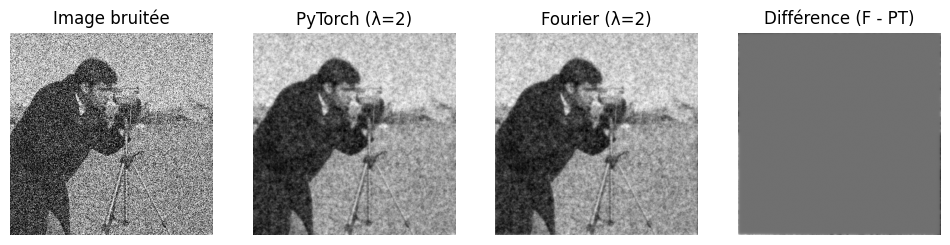

Noisy min: 0.0000, max: 1.0000, mean: 0.5069, shape: (512, 512), dtype: float64
PyTorch min: 0.1065, max: 0.8553, mean: 0.5069, shape: (512, 512), dtype: float32
Fourier min: 0.1065, max: 0.8553, mean: 0.5069, shape: (512, 512), dtype: float64


In [16]:
# DENOISING - QUALITATIVE COMPARISON BETWEEN FOURIER AND PYTORCH

# This are the values that gives the best results considering analytic and quantitative analysis 
lam = lambdas_tyk[4]
lr_tyk = lrs_tyk[4]
u_rec, loss_values = optimize_image(v_torch, lam, lr_tyk,
                                    reg_fn=tykhonov_reg, record_loss=True)
u_tyk = to_numpy(u_rec)

# Image restaurée par solution explicite avec Fourier
u_fourier = tykonov_fourier(v_torch, lam)

# Différence
im_diff = u_fourier - u_tyk

# Show everything on the same lin
show_images(
    [v, u_tyk, u_fourier, im_diff],
    titles=[
        "Image bruitée",
        f"PyTorch (λ={lam})",
        f"Fourier (λ={lam})",
        "Différence (F - PT)"
    ]  # ensure one single row
)
# Print statistics for each image to check their ranges:
for img, name in zip([v, u_tyk, u_fourier], ["Noisy", "PyTorch", "Fourier"]):
    arr = to_numpy(img)
    print(f"{name} min: {arr.min():.4f}, max: {arr.max():.4f}, mean: {arr.mean():.4f}, shape: {arr.shape}, dtype: {arr.dtype}")


# DENOISING - TOTAL VARIATION


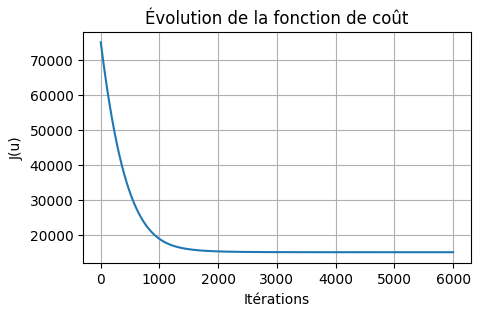

Convergence at iteration: 2677


In [17]:
# LOSS FUNCTION OF THE TV DENOISING FOR A CERTAIN LAMBDA
#arbitrary values to visualize the loss function
eps = 0.001
lam = 0.5
lr = 2/(1 + 8*lam/eps)
u_rec, loss_values = optimize_image(v_torch, lam, lr, n_iter = 6000, reg_fn=lambda u: tv_reg(u, eps=eps), record_loss=True)

plt.figure(figsize=(5,3))
plt.plot(loss_values)
plt.title("Évolution de la fonction de coût")
plt.xlabel("Itérations")
plt.ylabel("J(u)")
plt.grid(True)
plt.show()


# === compute convergence iteration ===
loss_arr = np.array(loss_values)
smooth_d = np.convolve(np.abs(np.diff(loss_arr)), np.ones(50)/50, mode='valid')
thr = 1e-1
idx = np.where(smooth_d < thr)[0]
print("Convergence at iteration:", idx[0] if len(idx)>0 else "not detected")


<>:60: SyntaxWarning: invalid escape sequence '\l'
<>:60: SyntaxWarning: invalid escape sequence '\l'
/var/folders/tr/h5v707gx7mx1xv9zf0xpkb5c0000gn/T/ipykernel_34586/3741594149.py:60: SyntaxWarning: invalid escape sequence '\l'
  plt.title('TV – PSNR, SSIM, MSE et MAE normalisés en fonction de $\lambda$')


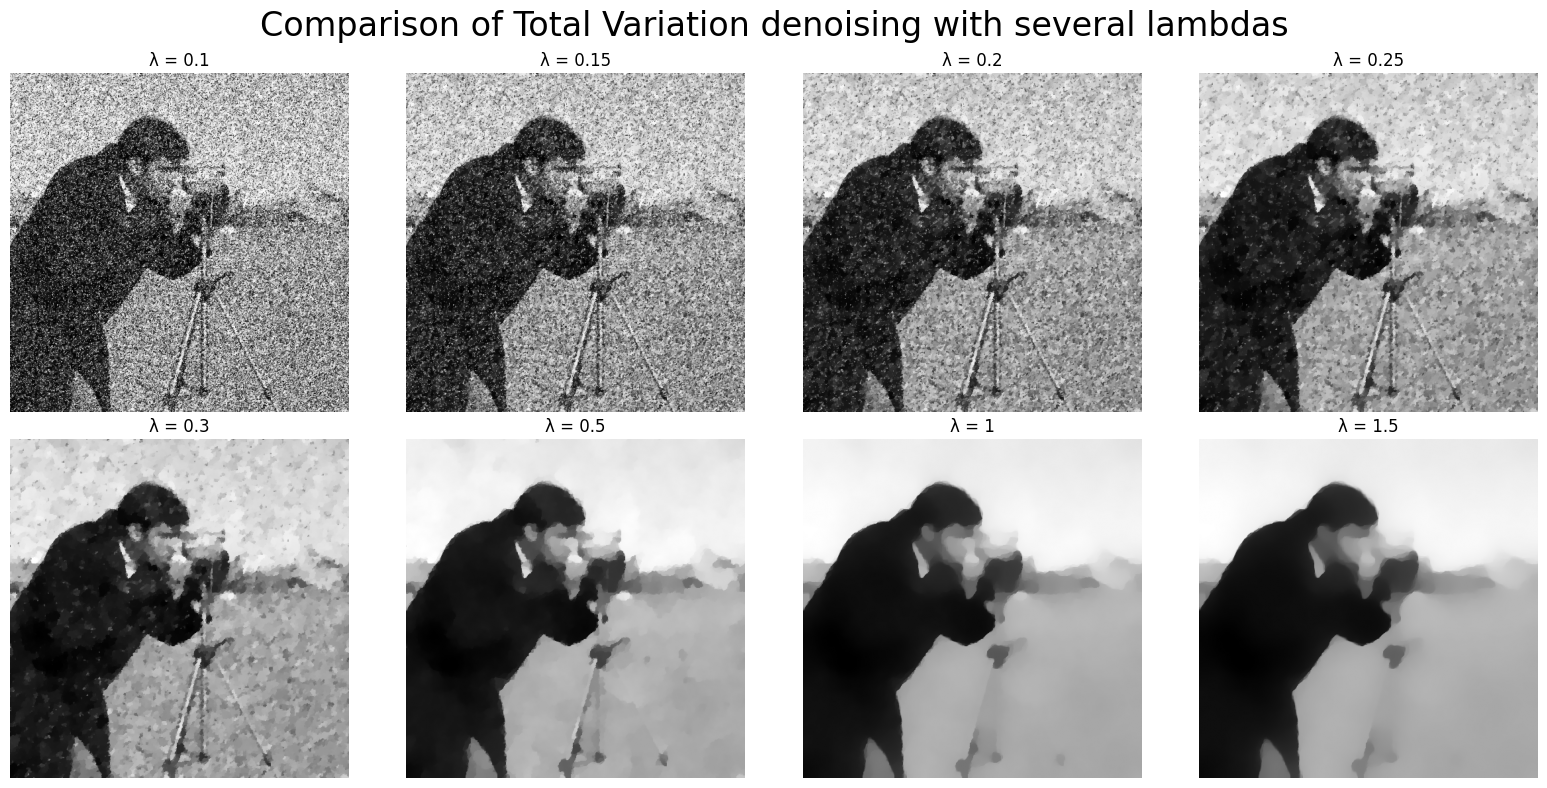

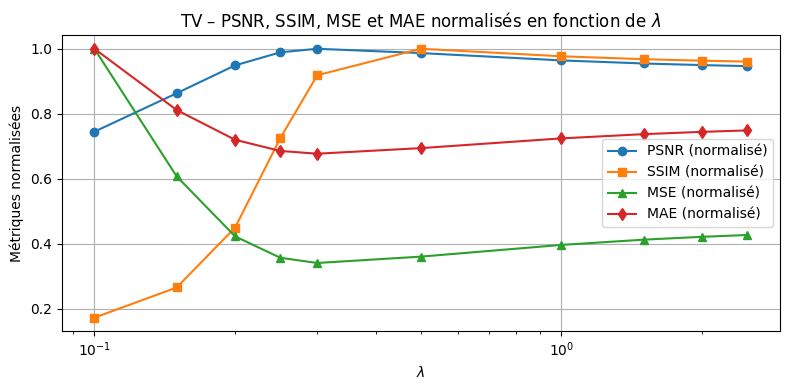

In [18]:
# TEST WITH SEVERAL LAMBDAS
lambdas_TV = [0.1, 0.15, 0.2, 0.25, 0.3, 0.5, 1, 1.5, 2, 2.5]
eps = 0.001
lrs_TV = [2/(1 + 8*lam/eps) for lam in lambdas_TV]
n_iter_TV = 5000

results = []
psnr_tv, ssim_tv, mse_tv, mae_tv = [], [], [], []

for lam, lr in zip(lambdas_TV, lrs_TV):
    u_t = optimize_image(
        v_torch, lam, lr,
        n_iter=n_iter_TV,
        reg_fn=lambda u: tv_reg(u, eps),
        record_loss=False
    )
    u_np = u_t.detach().cpu().numpy()
    results.append((lam, u_np))
    psnr_tv.append(psnr_np(u0, u_np))
    ssim_tv.append(ssim(u0, u_np, data_range=1.0))
    mse_tv.append(np.mean((u0 - u_np)**2))
    mae_tv.append(np.mean(np.abs(u0 - u_np)))

# visualisation
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (lam, u_img) in zip(axes.flatten(), results):
    ax.imshow(u_img, cmap='gray')
    ax.set_title(f"λ = {lam}")
    ax.axis('off')

fig.suptitle("Comparison of Total Variation denoising with several lambdas", fontsize=24)
plt.subplots_adjust(top=0.88)
plt.tight_layout()
plt.show()

# --- conversion en numpy ---
psnr_tv = np.array(psnr_tv)
ssim_tv = np.array(ssim_tv)
mse_tv  = np.array(mse_tv)
mae_tv  = np.array(mae_tv)

# --- normalisation (0–1) par le max de chaque métrique ---
psnr_tv_n = psnr_tv / psnr_tv.max()
ssim_tv_n = ssim_tv / ssim_tv.max()
mse_tv_n  = mse_tv  / mse_tv.max()
mae_tv_n  = mae_tv  / mae_tv.max()

# === plot unique : toutes les métriques normalisées vs lambda ===
plt.figure(figsize=(8, 4))

plt.plot(lambdas_TV, psnr_tv_n, marker='o', label='PSNR (normalisé)')
plt.plot(lambdas_TV, ssim_tv_n, marker='s', label='SSIM (normalisé)')
plt.plot(lambdas_TV, mse_tv_n,  marker='^', label='MSE (normalisé)')
plt.plot(lambdas_TV, mae_tv_n,  marker='d', label='MAE (normalisé)')

plt.xscale('log')  # optionnel, tu peux enlever si tu veux un axe linéaire
plt.xlabel(r'$\lambda$')
plt.ylabel('Métriques normalisées')
plt.title('TV – PSNR, SSIM, MSE et MAE normalisés en fonction de $\lambda$')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()




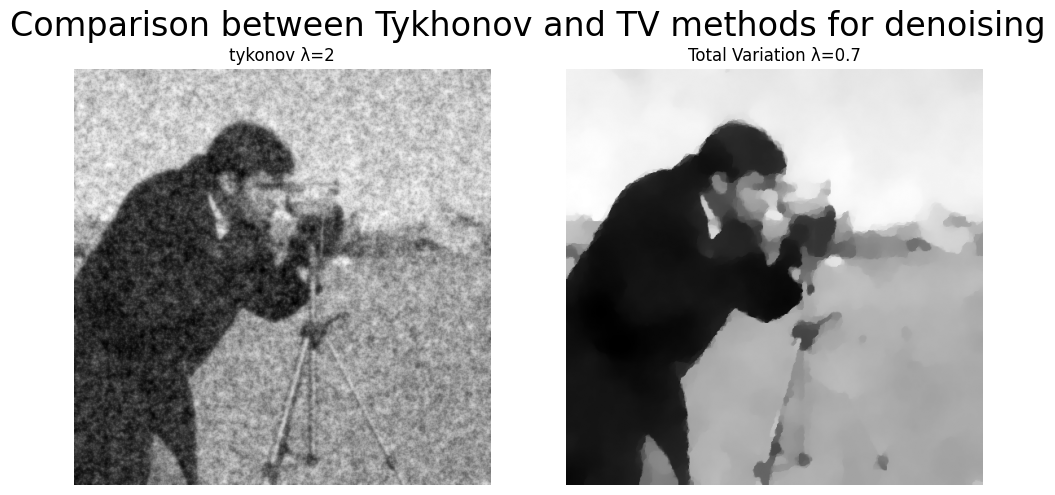


=== Quantitative comparison ===
tykonov (λ=2):
  PSNR = 17.95 dB
  MSE  = 0.0161
  MAE  = 0.1076
  SSIM = 0.337

Total Variation (λ=0.7, ε=0.001):
  PSNR = 18.02 dB
  MSE  = 0.0158
  MAE  = 0.1082
  SSIM = 0.558


In [19]:
# DENOISING - COMPARISON BETWEEEN TYKHONOV AND TOTAL VARIATION ANALYTICLY AND QUANTITATIVLY

# --- tykonov ---
lam_tyk = 2
lr_tyk = 1 / (1 + 16*lam_tyk)
u_tyk= optimize_image(
    v_torch, lam_tyk, lr_tyk,
    n_iter=500,
    reg_fn=tykhonov_reg,
    record_loss=False
)
u_tyk_np = u_tyk.detach().cpu().numpy()

# --- Total Variation ---
lam_tv = 0.7
lr_tv = 1 / (1 + (8*lam_tv/eps))
u_tv = optimize_image(
    v_torch, lam_tv, lr_tv,
    n_iter=7000,
    reg_fn=lambda u: tv_reg(u, eps),
    record_loss=False
)
u_tv_np = u_tv.detach().cpu().numpy()


fig, axes = plt.subplots(1,2, figsize=(10,5))
axes[0].imshow(u_tyk_np, cmap='gray')
axes[0].set_title(f"tykonov λ={lam_tyk}")
axes[0].axis('off')

axes[1].imshow(u_tv_np, cmap='gray')
axes[1].set_title(f"Total Variation λ={lam_tv}")
axes[1].axis('off')

fig.suptitle("Comparison between Tykhonov and TV methods for denoising", fontsize=24)
plt.subplots_adjust(top=0.88)
plt.tight_layout()
plt.show()

# --- tykonov ---
psnr_tyk = psnr_np(u0, u_tyk_np)
mse_tyk  = mse_np(u0, u_tyk_np)
mae_tyk  = mae_np(u0, u_tyk_np)
ssim_tyk = ssim(u0, u_tyk_np, data_range=1.0)

# --- TV ---
psnr_tv = psnr_np(u0, u_tv_np)
mse_tv  = mse_np(u0, u_tv_np)
mae_tv  = mae_np(u0, u_tv_np)
ssim_tv = ssim(u0, u_tv_np, data_range=1.0)

# ============================================================
# === Print results in clean format ===========================
# ============================================================

print("\n=== Quantitative comparison ===")
print(f"tykonov (λ={lam_tyk}):")
print(f"  PSNR = {psnr_tyk:.2f} dB")
print(f"  MSE  = {mse_tyk:.4f}")
print(f"  MAE  = {mae_tyk:.4f}")
print(f"  SSIM = {ssim_tyk:.3f}")

print(f"\nTotal Variation (λ={lam_tv}, ε={eps}):")
print(f"  PSNR = {psnr_tv:.2f} dB")
print(f"  MSE  = {mse_tv:.4f}")
print(f"  MAE  = {mae_tv:.4f}")
print(f"  SSIM = {ssim_tv:.3f}")





# DEBLURING

In [20]:

# BLUR FUNCTIONS
def periodic_conv2d(u, k):
    """Periodic (FFT-based) 2D convolution. u, k: (M,N) float32 torch tensors."""
    uf = fft2(u)
    kf = fft2(k)
    return torch.real(ifft2(uf * kf))

pi = torch.pi

# LOSS FUNCTIONS for deblurring
def deblur_tykhonov_loss(u, k, v, lam):
    conv_u = periodic_conv2d(u, k)
    fidelity = 0.5 * torch.sum((conv_u - v)**2)
    reg = lam * tykhonov_reg(u)
    return fidelity + reg

def deblur_tv_loss(u, k, v, lam, eps_tv=1e-3):
    conv_u = periodic_conv2d(u, k)
    fidelity = 0.5 * torch.sum((conv_u - v)**2)
    reg = lam * tv_reg(u, eps=eps_tv)
    return fidelity + reg

# OPTIMIZATION runner function
def run_deblur(method='tv',
               lam=1.0,
               eps_tv=1e-3,
               n_iter=20000,
               k=None,
               v=None):
    """method: 'tv' or 'tyk'
       k : noyau de convolution (torch tensor)
       v : image floutée (torch tensor)
    """
    # fallback sur les variables globales si pas données
    if k is None:
        raise ValueError("k peut pas être None")
    else:
        k_torch = k.clone().detach().float()

    if v is None:
        raise ValueError("v peut pas être None")
    else:
        v_torch = v.clone().detach().float()

    # variable à optimiser
    guess = v_torch.clone().detach().float().requires_grad_(True)

    # ----- calcul de ||A^T A|| via FFT du noyau k -----
    H = torch.fft.fft2(k_torch, s=v_torch.shape[-2:])
    norm_A2 = (H.abs() ** 2).max().item()   # ≈ ||A^T A||

    if method == 'tv':
        # L ≈ ||A^T A|| + 8 λ / ε
        L = norm_A2 + 8.0 * lam / eps_tv
        lr = 1.9 / L
        loss_func = lambda U: deblur_tv_loss(U, k_torch, v_torch, lam, eps_tv=eps_tv)

    elif method == 'tyk':
        # L ≈ ||A^T A|| + 16 λ
        L = norm_A2 + 16.0 * lam
        lr = 0.9 / L
        loss_func = lambda U: deblur_tykhonov_loss(U, k_torch, v_torch, lam)

    else:
        raise ValueError("method must be 'tv' or 'tyk'")

    opt = torch.optim.SGD([guess], lr=lr)
    loss_values = []

    for i in range(n_iter):
        opt.zero_grad(set_to_none=True)
        loss = loss_func(guess)
        loss.backward()
        opt.step()
        with torch.no_grad():
            guess.clamp_(0, 1)

        loss_values.append(loss.item())

    restored = guess.detach().cpu().numpy()
    return restored, loss_values, lr



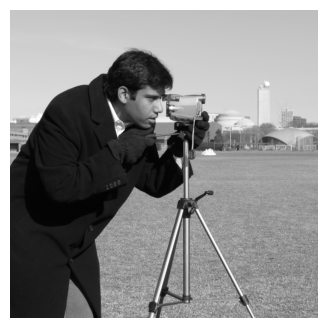

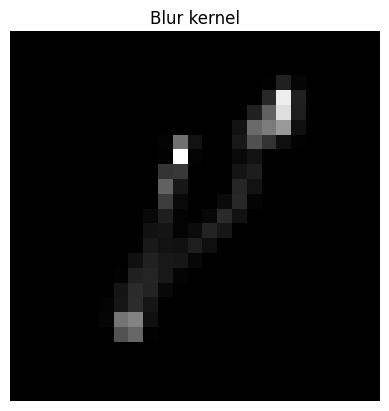

In [21]:
# where we got the kernels, our mentor shared this with us
# !wget https://perso.telecom-paristech.fr/aleclaire/mva/tpdeblur.zip
# !unzip tpdeblur.zip

# Load image
u0 = img_as_float(data.camera()) # or desired image
M, N = u0.shape
show_images([u0])

# Load a blur kernel
kt = torch.tensor(np.loadtxt('kernels/kernel8.txt'))
# kt = np.loadtxt('kernels/levin7.txt')
(m,n) = kt.shape
plt.imshow(kt, cmap='gray')
plt.title('Blur kernel')
plt.axis('off')
plt.show()

# Embed the kernel in a MxN image, and put center at pixel (0,0)
k = torch.zeros((M,N))
k[0:m,0:n] = kt/torch.sum(kt)
k = torch.roll(k,(-int(m/2),-int(n/2)),(0,1))
fk = fft2(k)
fk = fk.to(dtype=torch.complex64)

/var/folders/tr/h5v707gx7mx1xv9zf0xpkb5c0000gn/T/ipykernel_34586/1646930899.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  fk_torch = torch.tensor(fk, dtype=torch.complex64)


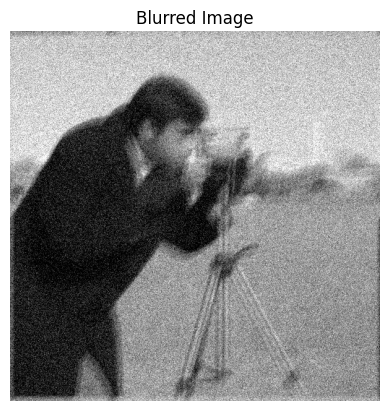

In [22]:
# Compute the degraded image v = k*u0 + w  (convolution with periodic boundary conditions)

sigma = 0.1 # used in this case. Justified in the report
# sigma = 0.5

# confirm u0 and fk are tensors
u0_torch = torch.tensor(u0, dtype=torch.float32)
fk_torch = torch.tensor(fk, dtype=torch.complex64)

# convolution with periodic boundary
u0_fft = fft2(u0_torch)
conv_u0 = ifft2(u0_fft * fk_torch)
conv_u0 = torch.real(conv_u0)
v = conv_u0 + sigma * torch.randn_like(conv_u0)
v = v.clamp(0.0, 1.0)

# plot the blurred image
plt.figure(dpi=100)
plt.imshow(v.detach().cpu().numpy(), cmap='gray')
plt.title('Blurred Image')
plt.axis('off')
plt.show()
plt.imsave('blurred_image.png', v.cpu().numpy(), cmap='gray')





<>:43: SyntaxWarning: invalid escape sequence '\l'
<>:43: SyntaxWarning: invalid escape sequence '\l'
/var/folders/tr/h5v707gx7mx1xv9zf0xpkb5c0000gn/T/ipykernel_34586/4012136276.py:43: SyntaxWarning: invalid escape sequence '\l'
  plt.title('Deblurring tykonov - normalized metrics based on $\lambda$')


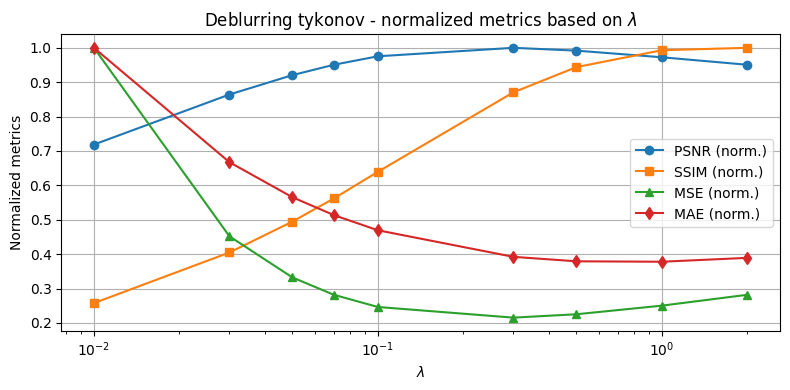

In [23]:
# Quantitative study of the influence of λ on the tykonov deblurring

lambdas_tyk = [0.01, 0.03, 0.05, 0.07, 0.1, 0.3, 0.5, 1, 2]
#lambdas_tyk = [0.01, 0.03, 0.05, 0.07, 0.1]
#lambdas_tyk = [0.005, 0.007, 0.01, 0.03, 0.05]
psnr_tyk, ssim_tyk, mse_tyk, mae_tyk = [], [], [], []

for lam in lambdas_tyk:
    # n_iter can be adapted if necessary
    rest_tyk_lam, loss_tyk_lam, lr_tyk_lam = run_deblur(
        method='tyk',
        lam=lam,
        n_iter=200,
        k=k,
        v=v
    )
    u_np = rest_tyk_lam

    psnr_tyk.append(psnr_np(u0, u_np))
    ssim_tyk.append(ssim(u0, u_np, data_range=1.0))
    mse_tyk.append(np.mean((u0 - u_np) ** 2))
    mae_tyk.append(np.mean(np.abs(u0 - u_np)))

psnr_tyk = np.array(psnr_tyk)
ssim_tyk = np.array(ssim_tyk)
mse_tyk  = np.array(mse_tyk)
mae_tyk  = np.array(mae_tyk)

# Normalisation (0–1) in function of the maximum of each metric
psnr_tyk_n = psnr_tyk / psnr_tyk.max()
ssim_tyk_n = ssim_tyk / ssim_tyk.max()
mse_tyk_n  = mse_tyk / mse_tyk.max()
mae_tyk_n  = mae_tyk  / mae_tyk.max()

plt.figure(figsize=(8, 4))
plt.plot(lambdas_tyk, psnr_tyk_n, marker='o', label='PSNR (norm.)')
plt.plot(lambdas_tyk, ssim_tyk_n, marker='s', label='SSIM (norm.)')
plt.plot(lambdas_tyk, mse_tyk_n,  marker='^', label='MSE (norm.)')
plt.plot(lambdas_tyk, mae_tyk_n,  marker='d', label='MAE (norm.)')
plt.xscale('log')
plt.xlabel(r'$\lambda$')
plt.ylabel('Normalized metrics')
plt.title('Deblurring tykonov - normalized metrics based on $\lambda$')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


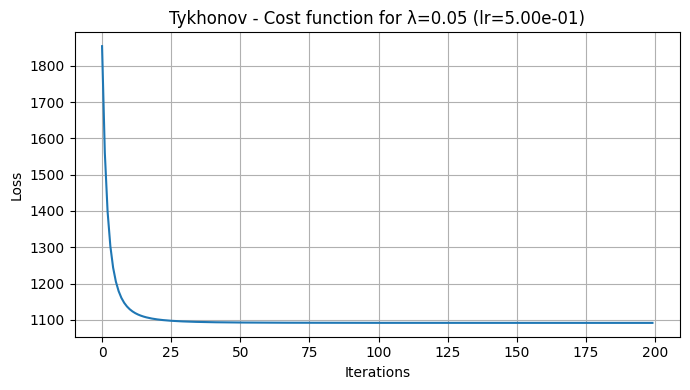

In [24]:
# Displaying the cost function for a single λ
lam_plot = 0.05   # change if desired to plot another lambda
n_iter_plot = 200

_, loss_plot, lr_plot = run_deblur(
    method='tyk',
    lam=lam_plot,
    n_iter=n_iter_plot,
    k=k,
    v=v
)

iters = np.arange(len(loss_plot))

plt.figure(figsize=(7, 4))
plt.plot(iters, loss_plot)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title(f"Tykhonov - Cost function for λ={lam_plot} (lr={lr_plot:.2e})")
plt.grid(True)
plt.tight_layout()
plt.show()


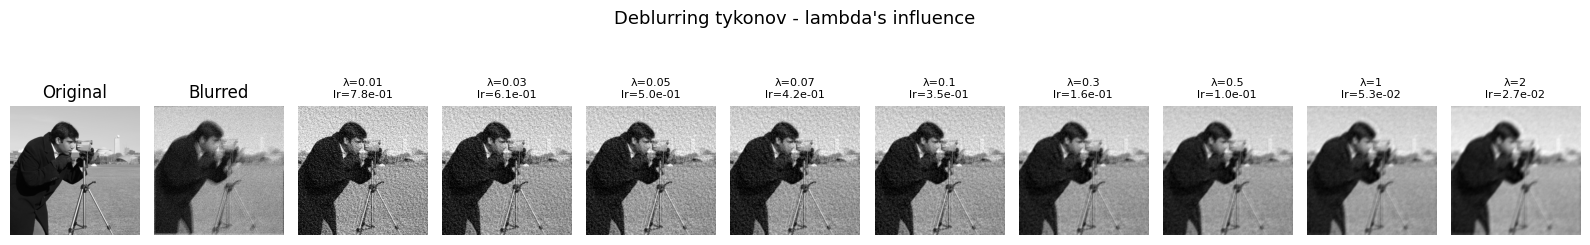

In [25]:
# Qualitative study: restored images side by side for different lambdas

#lambdas_show = [0.1, 0.3, 0.5, 1, 2, 3, 5, 7, 10]
lambdas_show = [0.01, 0.03, 0.05, 0.07, 0.1, 0.3, 0.5, 1, 2]

n_iter_show = 200

rest_images = []

for lam in lambdas_show:
    restored, _, lr_tmp = run_deblur(
        method='tyk',
        lam=lam,
        n_iter=n_iter_show,
        k=k,
        v=v
    )
    rest_images.append((lam, restored, lr_tmp))

plt.figure(figsize=(16, 3))

# First column: Original
plt.subplot(1, len(rest_images) + 2, 1)
plt.imshow(u0, cmap='gray')
plt.title("Original")
plt.axis("off")

# Second column: : Blurred
plt.subplot(1, len(rest_images) + 2, 2)
plt.imshow(v, cmap='gray')
plt.title("Blurred")
plt.axis("off")

# Following columns : different lambdas
for i, (lam, img, lr) in enumerate(rest_images):
    plt.subplot(1, len(rest_images) + 2, i + 3)
    plt.imshow(img, cmap='gray')
    plt.title(f"λ={lam}\nlr={lr:.1e}", fontsize=8)
    plt.axis("off")

plt.suptitle("Deblurring tykonov - lambda's influence", fontsize=13)
plt.tight_layout()
plt.show()


<>:49: SyntaxWarning: invalid escape sequence '\l'
<>:49: SyntaxWarning: invalid escape sequence '\l'
/var/folders/tr/h5v707gx7mx1xv9zf0xpkb5c0000gn/T/ipykernel_34586/2694098801.py:49: SyntaxWarning: invalid escape sequence '\l'
  plt.title('Deblurring TV - normalized metrics based on $\lambda$')


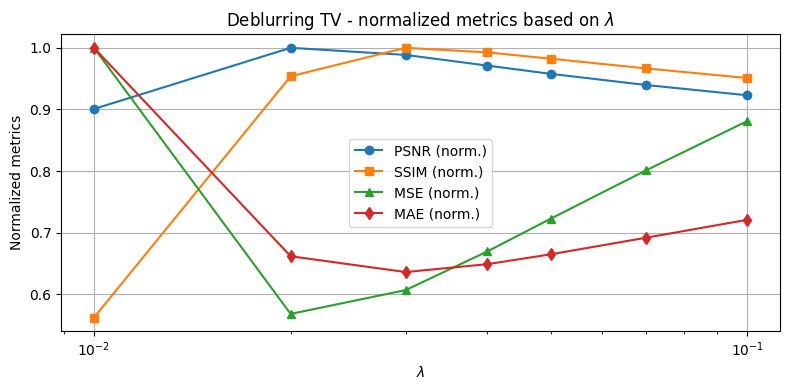

In [26]:
# Quantitative study of the influence of λ on the TV deblurring

lambdas_tv = [0.01, 0.02, 0.03, 0.04, 0.05, 0.07, 0.1]
eps_tv = 0.001
psnr_tv, ssim_tv, mse_tv, mae_tv = [], [], [], []


rest_tv_images = []   # tuple list (lambda, image, lr)

for lam in lambdas_tv:
    rest_tv_lam, loss_tv_lam, lr_tv_lam = run_deblur(
        method='tv',
        lam=lam,
        eps_tv=eps_tv,
        n_iter=1500,      # TV needs more iterations than tykh
        k=k,
        v=v
    )
    u_np = rest_tv_lam  # its in numpy

    # metrics
    psnr_tv.append(psnr_np(u0, u_np))
    ssim_tv.append(ssim(u0, u_np, data_range=1.0))
    mse_tv.append(np.mean((u0 - u_np) ** 2))
    mae_tv.append(np.mean(np.abs(u0 - u_np)))

    # store it for following parts (qualitative analysis)
    rest_tv_images.append((lam, u_np, lr_tv_lam))

psnr_tv = np.array(psnr_tv)
ssim_tv = np.array(ssim_tv)
mse_tv  = np.array(mse_tv)
mae_tv  = np.array(mae_tv)

# Normalisation (0–1) in function of the maximum of each metric
psnr_tv_n = psnr_tv / psnr_tv.max()
ssim_tv_n = ssim_tv / ssim_tv.max()
mse_tv_n  = mse_tv  / mse_tv.max()
mae_tv_n  = mae_tv  / mae_tv.max()

plt.figure(figsize=(8, 4))
plt.plot(lambdas_tv, psnr_tv_n, marker='o', label='PSNR (norm.)')
plt.plot(lambdas_tv, ssim_tv_n, marker='s', label='SSIM (norm.)')
plt.plot(lambdas_tv, mse_tv_n,  marker='^', label='MSE (norm.)')
plt.plot(lambdas_tv, mae_tv_n,  marker='d', label='MAE (norm.)')
plt.xscale('log')
plt.xlabel(r'$\lambda$')
plt.ylabel('Normalized metrics')
plt.title('Deblurring TV - normalized metrics based on $\lambda$')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


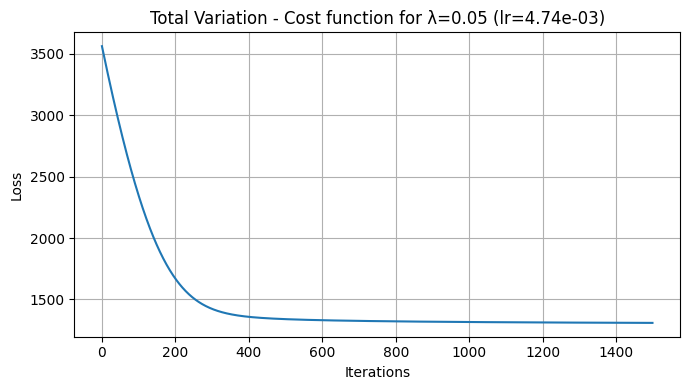

In [27]:
# Displaying the cost function for a single λ
lam_plot = 0.05   # change if desired to plot another lambda
n_iter_plot = 1500

_, loss_plot, lr_plot = run_deblur(
    method='tv',
    lam=lam_plot,
    n_iter=n_iter_plot,
    k=k,
    v=v
)

iters = np.arange(len(loss_plot))

plt.figure(figsize=(7, 4))
plt.plot(iters, loss_plot)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title(f"Total Variation - Cost function for λ={lam_plot} (lr={lr_plot:.2e})")
plt.grid(True)
plt.tight_layout()
plt.show()


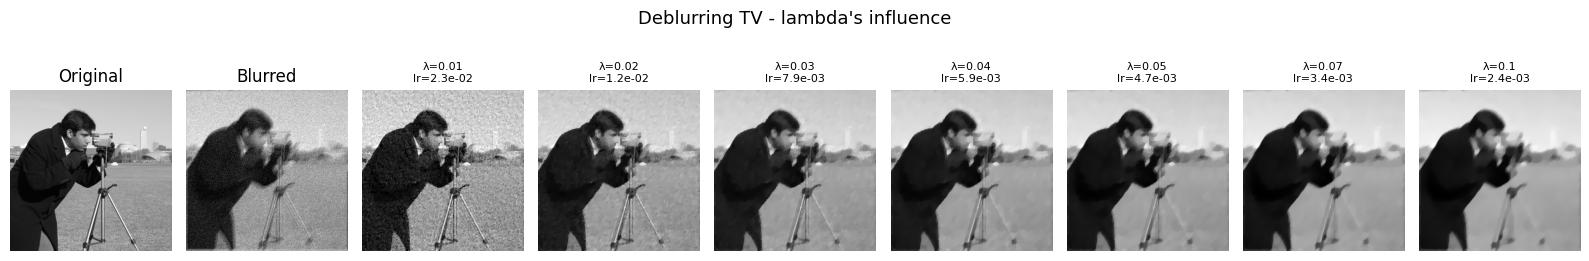

In [28]:
# Qualitative study: restored images side by side for different lambdas

plt.figure(figsize=(16, 3))

# First column: Original
plt.subplot(1, len(rest_tv_images) + 2, 1)
plt.imshow(u0, cmap='gray')
plt.title("Original")
plt.axis("off")

# Second column: : Blurred
plt.subplot(1, len(rest_tv_images) + 2, 2)
plt.imshow(v, cmap='gray')
plt.title("Blurred")
plt.axis("off")

# Following columns : results for each lambda
for i, (lam, img, lr_tv_lam) in enumerate(rest_tv_images):
    plt.subplot(1, len(rest_tv_images) + 2, i + 3)
    plt.imshow(img, cmap='gray')
    plt.title(f"λ={lam}\nlr={lr_tv_lam:.1e}", fontsize=8)
    plt.axis("off")

plt.suptitle("Deblurring TV - lambda's influence", fontsize=13)
plt.tight_layout()
plt.show()


Running TV: lam=0.03, eps=0.005
Running TV: lam=0.03, eps=0.01
Running TV: lam=0.03, eps=0.015
Running TV: lam=0.05, eps=0.005
Running TV: lam=0.05, eps=0.01
Running TV: lam=0.05, eps=0.015


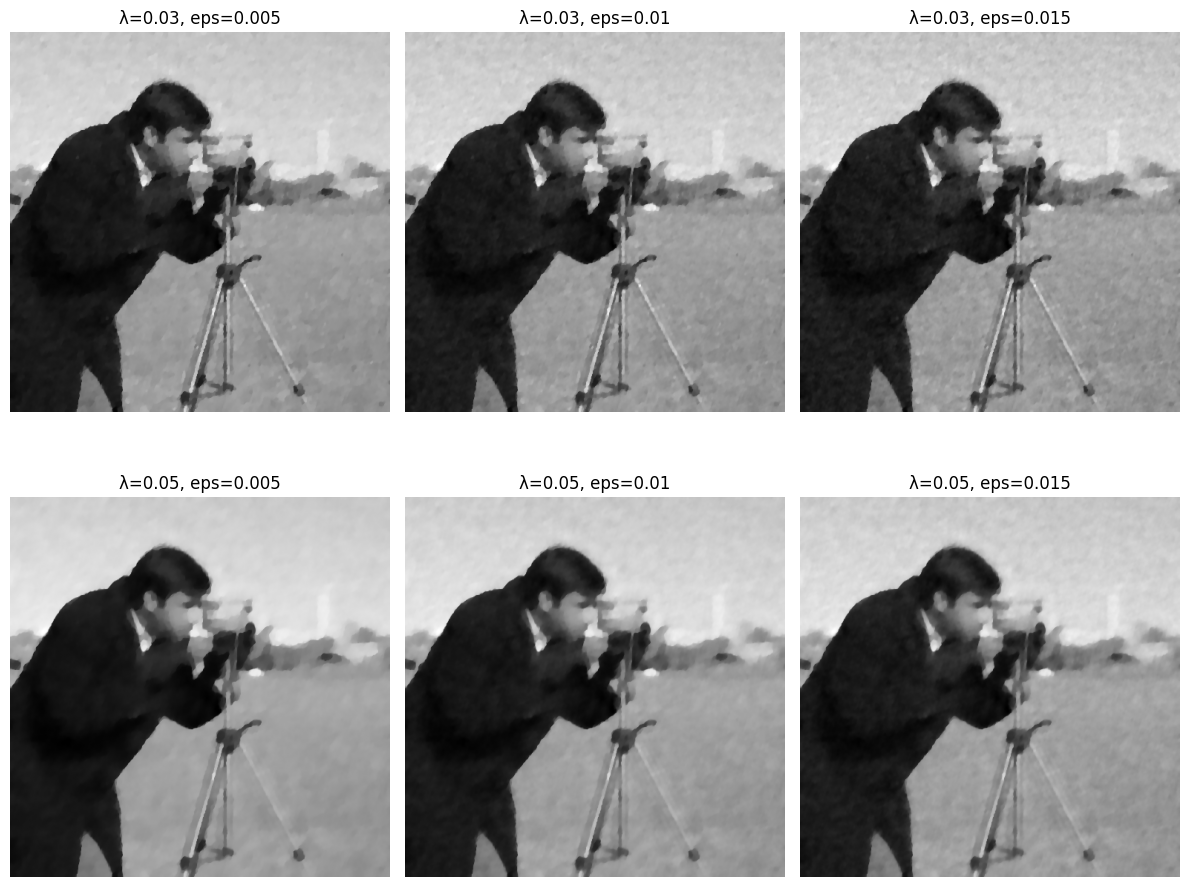

In [29]:
# TEST of different PARAMETERS CONFIGURATION
# in order to choose which ones work best for the deblurring process

# choose the parameter test grid
lams = [0.03, 0.05]
eps_list = [0.005, 0.01, 0.015]

results = {}

# run TV deblurring for each (lambda, eps) 
for lam in lams:
    for eps in eps_list:
        print(f"Running TV: lam={lam}, eps={eps}")
        rest, loss, lr_used = run_deblur(
            method='tv',
            lam=lam,
            eps_tv=eps,
            n_iter=1500,
            k = k, 
            v = v
        )

        # rest is already numpy → just squeeze
        results[(lam, eps)] = rest.squeeze()

# Plot
fig, axes = plt.subplots(len(lams), len(eps_list), figsize=(12, 10))

for i, lam in enumerate(lams):
    for j, eps in enumerate(eps_list):
        ax = axes[i, j]
        ax.imshow(results[(lam, eps)], cmap='gray')
        ax.set_title(f"λ={lam}, eps={eps}")
        ax.axis('off')

plt.tight_layout()
plt.show()


In [30]:
# Runs both methods with chosen configurations

# tykonov (faster convergence)
lam_tyk = 0.5
rest_tyk, loss_tyk, lr_tyk = run_deblur(method='tyk', lam=lam_tyk, n_iter=500, k = k, v = v)

# TV (needs more iterations)
lam_tv = 0.03
eps_tv = 0.005
rest_tv, loss_tv, lr_tv = run_deblur(method='tv', lam=lam_tv, eps_tv=eps_tv, n_iter=1500, k = k, v = v)

# save results
plt.imsave('deblur_tykonov.png', rest_tyk, cmap='gray')
plt.imsave('deblur_tv.png', rest_tv, cmap='gray')


In [31]:
# Compute metrics 
def compute_metrics(u_ref, u_est):
    u_ref = np.array(u_ref)
    u_est = np.array(u_est)
    mse  = np.mean((u_ref - u_est)**2)
    mae  = np.mean(np.abs(u_ref - u_est))
    rmse = np.sqrt(mse)
    psnr = 20 * np.log10(1.0 / rmse)
    ssim_val = ssim(u_ref, u_est, data_range=1.0)
    return psnr, mse, mae, ssim_val

psnr_tyk, mse_tyk, mae_tyk, ssim_tyk = compute_metrics(u0, rest_tyk)
psnr_tv,  mse_tv,  mae_tv,  ssim_tv  = compute_metrics(u0, rest_tv)

print("\n=== Quantitative comparison ===")
print(f"tykonov (λ={lam_tyk}):")
print(f"  PSNR = {psnr_tyk:.2f} dB")
print(f"  MSE  = {mse_tyk:.4f}")
print(f"  MAE  = {mae_tyk:.4f}")
print(f"  SSIM = {ssim_tyk:.3f}")

print(f"\nTotal Variation (λ={lam_tv}, ε={eps_tv}):")
print(f"  PSNR = {psnr_tv:.2f} dB")
print(f"  MSE  = {mse_tv:.4f}")
print(f"  MAE  = {mae_tv:.4f}")
print(f"  SSIM = {ssim_tv:.3f}")



=== Quantitative comparison ===
tykonov (λ=0.5):
  PSNR = 23.52 dB
  MSE  = 0.0044
  MAE  = 0.0421
  SSIM = 0.576

Total Variation (λ=0.03, ε=0.005):
  PSNR = 25.07 dB
  MSE  = 0.0031
  MAE  = 0.0337
  SSIM = 0.668


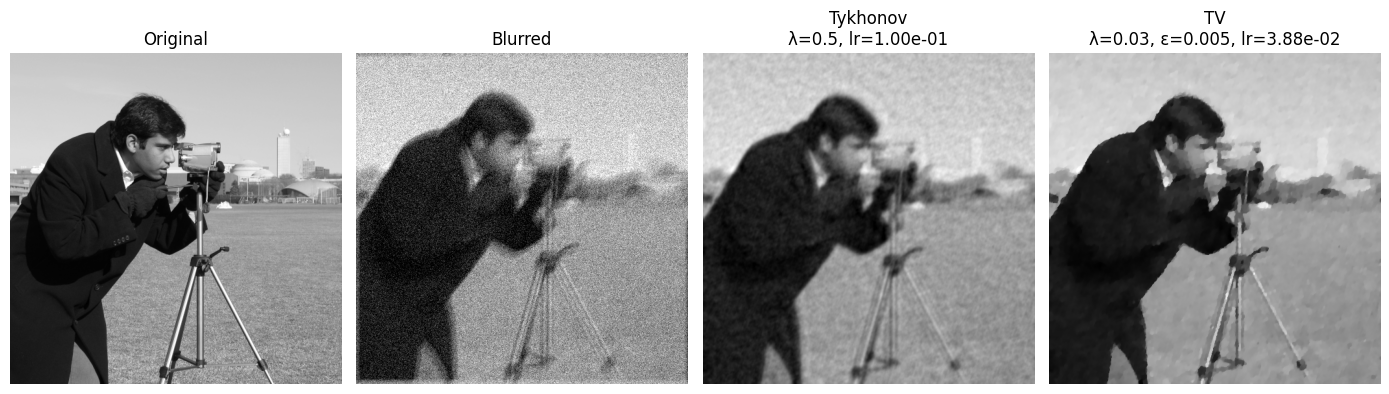

In [32]:
# Image visualisation: Original, Blurred, tykonov, TV

plt.figure(figsize=(14, 4))

#   Column 1: original
plt.subplot(1, 4, 1)
plt.imshow(u0, cmap='gray')
plt.title("Original")
plt.axis("off")

# Column 2 : blur
plt.subplot(1, 4, 2)
plt.imshow(v, cmap='gray')
plt.title("Blurred")
plt.axis("off")

# Column 3 : Tykhonov deblurring
plt.subplot(1, 4, 3)
plt.imshow(rest_tyk, cmap='gray')
plt.title(f"Tykhonov\nλ={lam_tyk}, lr={lr_tyk:.2e}")
plt.axis("off")

# Column 4 : TV deblurring
plt.subplot(1, 4, 4)
plt.imshow(rest_tv, cmap='gray')
plt.title(f"TV\nλ={lam_tv}, ε={eps_tv}, lr={lr_tv:.2e}")
plt.axis("off")

plt.tight_layout()
plt.show()



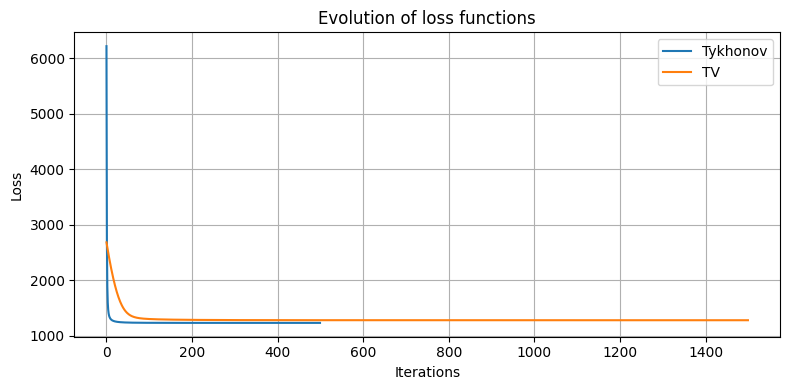

In [33]:
# Loss curves for both methods

iters_tyk = np.arange(len(loss_tyk))
iters_tv  = np.arange(len(loss_tv))

plt.figure(figsize=(8, 4))
plt.plot(iters_tyk, loss_tyk, label='Tykhonov')
plt.plot(iters_tv,  loss_tv,  label='TV')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('Evolution of loss functions')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()